# Misión 2: Recomendaciones Inteligentes — Clustering de Productos
## Brazilian E-Commerce Public Dataset by Olist

La idea es agrupar productos parecidos para poder recomendar mejor y entender el catálogo.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# para el clustering y reducción de dimensiones
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [3]:
from pathlib import Path
DATA_PATH = Path('Datasets')

order_items = pd.read_csv(DATA_PATH / 'olist_order_items_dataset.csv')
products = pd.read_csv(DATA_PATH / 'olist_products_dataset.csv')
reviews = pd.read_csv(DATA_PATH / 'olist_order_reviews_dataset.csv')

print(f"order_items:  {order_items.shape}")
print(f"products:     {products.shape}")
print(f"reviews:      {reviews.shape}")

order_items:  (112650, 7)
products:     (32951, 9)
reviews:      (99224, 7)

## Preparar features

Para agrupar los productos necesitamos 4 características:
- **price**: precio promedio del producto
- **freight_value**: flete promedio
- **review_score**: calificación promedio
- **total_sales**: cantidad de veces que se vendió

In [16]:
# precio y flete promedio por producto
product_stats = order_items.groupby('product_id').agg(
    price=('price', 'mean'),
    freight_value=('freight_value', 'mean'),
    total_sales=('order_id', 'count')
).reset_index()

# tardé un rato en darme cuenta que reviews no tiene product_id directo
# hay que pasar por order_items para llegar al producto
review_scores = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

order_items_reviews = order_items[['order_id', 'product_id']].merge(review_scores, on='order_id')
product_reviews = order_items_reviews.groupby('product_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

# Unir todo
df = product_stats.merge(product_reviews, on='product_id', how='left')
df = df.dropna()

print(f"Productos para modelar: {df.shape[0]:,}")
print(df[['price', 'freight_value', 'review_score', 'total_sales']].describe().round(2))

Productos para modelar: 32,789
          price  freight_value  review_score  total_sales
count  32789.00       32789.00      32789.00     32789.00
mean     145.16          21.20          4.05         3.43
std      244.46          18.07          1.21        10.64
min        0.85           0.01          1.00         1.00
25%       39.90          13.60          3.60         1.00
50%       79.00          16.70          4.50         1.00
75%      154.94          21.83          5.00         3.00
max     6735.00         409.68          5.00       527.00


In [17]:
features = ['price', 'freight_value', 'review_score', 'total_sales']

# busqué cómo manejar valores extremos y encontré que log1p funciona bien
# price y total_sales tienen valores extremos, aplicar log1p antes de escalar
df_model = df.copy()
df_model['total_sales'] = np.log1p(df_model['total_sales'])
df_model['price'] = np.log1p(df_model['price'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[features])

print(f"Listo. Shape: {X_scaled.shape}")

Listo. Shape: (32789, 4)


## Elegir el número de clusters (K)

Probamos K entre 2 y 8 y usamos dos métodos:
- **Elbow method:** graficamos la inercia por K, buscamos donde la curva se aplana
- **Silhouette Score:** valores más cercanos a 1 indican clusters más separados

In [7]:
inercias = []
silhouettes = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, kmeans.labels_))
    print(f"K={k}: Inercia={kmeans.inertia_:.0f} | Silhouette={silhouette_score(X_scaled, kmeans.labels_):.4f}")

K=2: Inercia=106074 | Silhouette=0.3130
K=3: Inercia=84236 | Silhouette=0.3175
K=4: Inercia=63204 | Silhouette=0.3601
K=5: Inercia=50260 | Silhouette=0.3089
K=6: Inercia=45436 | Silhouette=0.2963
K=7: Inercia=41360 | Silhouette=0.2942
K=8: Inercia=38019 | Silhouette=0.2579

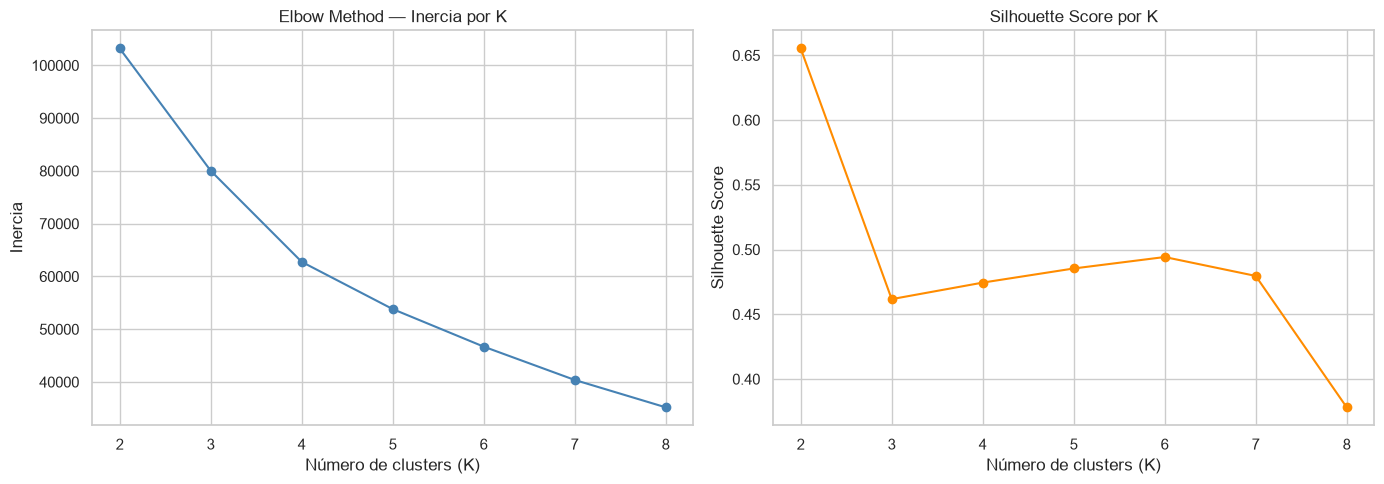

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
ax1.plot(k_range, inercias, marker='o', color='steelblue')
ax1.set_title('Elbow Method — Inercia por K')
ax1.set_xlabel('Número de clusters (K)')
ax1.set_ylabel('Inercia')

# Silhouette
ax2.plot(k_range, silhouettes, marker='o', color='darkorange')
ax2.set_title('Silhouette Score por K')
ax2.set_xlabel('Número de clusters (K)')
ax2.set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

## Entrenar K-Means con K=5

Mirando los gráficos, K=5 parece un buen balance — el codo se aplana ahí. El silhouette baja un poco respecto a K=4 pero con K=5 se pueden interpretar mejor los grupos.

In [ ]:
K_OPTIMO = 5

# entrenar con K=5 y asignar cluster a cada producto
kmeans = KMeans(n_clusters=K_OPTIMO, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(f"K-Means entrenado con K={K_OPTIMO}")
print("\nDistribución de productos por cluster:")
for cluster, count in df['cluster'].value_counts().sort_index().items():
    pct = count / len(df) * 100
    print(f"  Cluster {cluster}: {count:,} productos ({pct:.1f}%)")

K-Means entrenado con K=5

Distribución de productos por cluster:
  Cluster 0: 11,742 productos (35.8%)
  Cluster 1: 9,942 productos (30.3%)
  Cluster 2: 4,605 productos (14.0%)
  Cluster 3: 5,453 productos (16.6%)
  Cluster 4: 1,047 productos (3.2%)


## Perfil de cada cluster

Veamos qué características tiene cada grupo para darle un nombre de negocio.

In [ ]:
perfil = df.groupby('cluster')[features].mean().round(2)
perfil['n_productos'] = df.groupby('cluster').size()
print(perfil)

          price  freight_value  review_score  total_sales  n_productos
cluster                                                               
0         43.13          14.85          4.61         1.61        11742
1        248.32          23.26          4.61         1.62         9942
2         92.46          18.20          4.04        14.57         4605
3        124.77          19.23          1.84         1.56         5453
4        647.87          96.28          3.92         1.77         1047


In [13]:
nombres = {
    0: 'Económico',
    1: 'Premium',
    2: 'Alta Rotación / Best Sellers',
    3: 'Baja Calificación / Riesgo',
    4: 'Muy Caros'
}

df['cluster_nombre'] = df['cluster'].map(nombres)

print("Distribución final:")
for cluster, nombre in nombres.items():
    count = (df['cluster'] == cluster).sum()
    pct = count / len(df) * 100
    print(f"  {nombre}: {count:,} productos ({pct:.1f}%)")

Distribución final:
  Económico: 11,742 productos (35.8%)
  Premium: 9,942 productos (30.3%)
  Alta Rotación / Best Sellers: 4,605 productos (14.0%)
  Baja Calificación / Riesgo: 5,453 productos (16.6%)
  Muy Caros: 1,047 productos (3.2%)

## Visualización con PCA

Como tenemos 4 features no podemos graficar directamente. PCA las reduce a 2 (o 3) dimensiones para poder ver los clusters. Es solo para visualizar, no cambia el modelo.

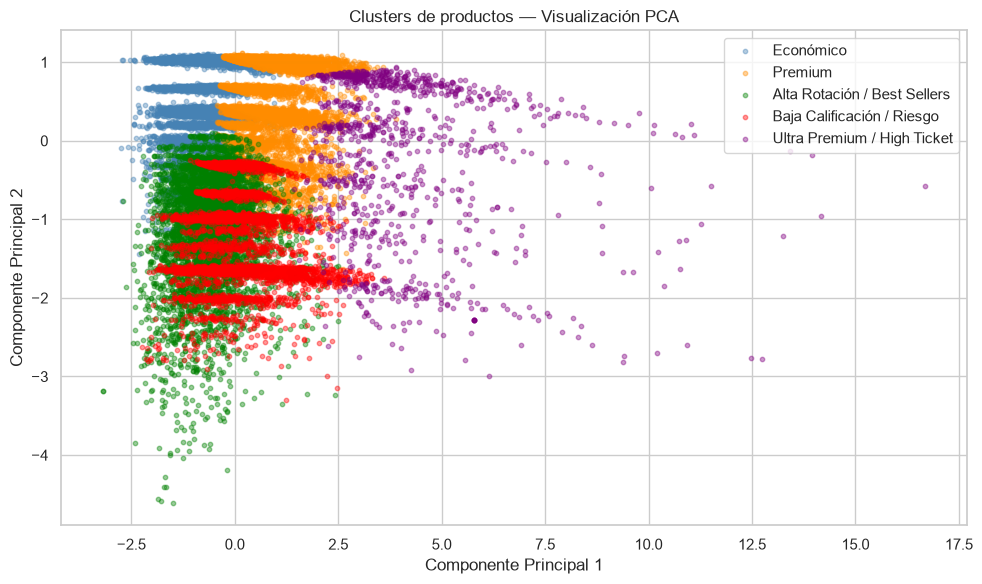


Varianza explicada por los 2 componentes: 61.6%


In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
colores = ['steelblue', 'darkorange', 'green', 'red', 'purple']

for cluster, nombre in nombres.items():
    mask = df['cluster'] == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                label=nombre, alpha=0.4, s=10, color=colores[cluster])

plt.title('Clusters de productos — Visualización PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f"\nVarianza explicada por los 2 componentes: {pca.explained_variance_ratio_.sum()*100:.1f}%")

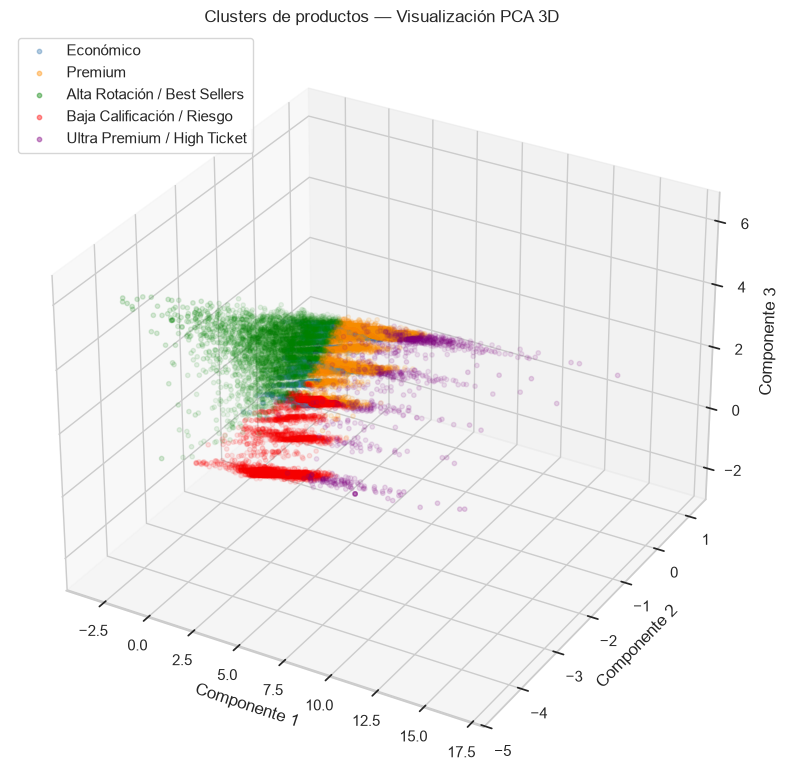


Varianza explicada por los 3 componentes: 85.9%


In [ ]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

colores = ['steelblue', 'darkorange', 'green', 'red', 'purple']

for cluster, nombre in nombres.items():
    mask = df['cluster'] == cluster
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], X_pca[mask, 2],
               label=nombre, alpha=0.4, s=10, color=colores[cluster])

ax.set_title('Clusters de productos — Visualización PCA 3D')
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_zlabel('Componente 3')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"\nVarianza explicada por los 3 componentes: {pca.explained_variance_ratio_.sum()*100:.1f}%")

## Conclusiones

Después de analizar el perfil de cada cluster:

- **Cluster 0 — Económico** (35.8%): precio bajo ~43, buen score 4.6
- **Cluster 1 — Premium** (30.3%): precio alto ~248, también buen score
- **Cluster 2 — Alta Rotación** (14.0%): precio medio pero se vende mucho, promedio 14.5 ventas
- **Cluster 3 — Baja Calificación** (16.6%): score 1.84, claramente productos con problemas
- **Cluster 4 — Muy Caros** (3.2%): precio ~648 y flete ~96, nicho muy específico

Lo más útil sería enfocarse en el Cluster 3 para mejorar calidad, y asegurar stock del Cluster 2.

## Nota sobre Pipeline y Overfitting en Clustering

K-Means no usa Pipeline de la misma manera que los modelos supervisados — no hay target que predecir ni train/test split clásico.

El equivalente al "overfitting" en clustering se analiza con la curva de inercia: si eligiéramos K muy alto (como K=8), el modelo se ajustaría demasiado a los datos y perdería generalidad. Por eso el método del codo ayuda a encontrar un K razonable.

Para los modelos supervisados (Misión 3 y 5) sí usé Pipeline explícitamente.